# Assessing The Impact of Socioeconomic Factors on School Performance

## Introduction

This project analyzes high school data and ACT scores to examine the relationship between socioeconomic factors and academic performance. A multiple linear regression model is used to assess the strength of these relationships and identify which socioeconomic variables are most strongly associated with academic performance.

The ACT is a standardized exam used by colleges and universities to measure academic readiness. The exam is graded on a scale of 1 to 36. According to summary statistics published by the ACT in 2023, 37% of high school graduates took the ACT, and the national average score was 19.5 (ACT, 2023). ACT scores can determine admission to a university, as well as influence the outcome of merit-based scholarships.

This study aims to determine whether ACT scores should continue to be used as a measure of student preparedness for college coursework or whether they are too heavily influenced by socioeconomic factors to be deemed useful.

## Data

The data for this project was from two sources. The school data was from the National Center for Education Statistics (NCES) and provided the data to determine if a school was a high school, based on the unique ID provided to each school. The other data source was from EdGap, which provided the data for each school's average ACT score, median household income, the percentage of students on a free/reduced price lunch, and the percentage of adults with a college degree.


## Data Preparation

Import relevant libraries for the project

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style(style="whitegrid")

Import data and assign to respective dataframes

In [2]:
edgap = pd.read_excel('/Users/michael/Documents/SeattleU/5100/Education/data/EdGap_data.xlsx')

/opt/anaconda3/lib/python3.13/site-packages/openpyxl/worksheet/_read_only.py:85: UserWarning: Unknown extension is not supported and will be removed
  for idx, row in parser.parse():


In [3]:
edgap.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7986 entries, 0 to 7985
Data columns (total 7 columns):
 #   Column                                           Non-Null Count  Dtype  
---  ------                                           --------------  -----  
 0   NCESSCH School ID                                7986 non-null   int64  
 1   CT Unemployment Rate                             7972 non-null   float64
 2   CT Pct Adults with College Degree                7973 non-null   float64
 3   CT Pct Childre In Married Couple Family          7961 non-null   float64
 4   CT Median Household Income                       7966 non-null   float64
 5   School ACT average (or equivalent if SAT score)  7986 non-null   float64
 6   School Pct Free and Reduced Lunch                7986 non-null   float64
dtypes: float64(6), int64(1)
memory usage: 436.9 KB


In [4]:
edgap.head()

,NCESSCH School ID,CT Unemployment Rate,CT Pct Adults with College Degree,CT Pct Childre In Married Couple Family,CT Median Household Income,School ACT average (or equivalent if SAT score),School Pct Free and Reduced Lunch
0,100001600143,0.117962,0.445283,0.346495,42820.0,20.433455,0.066901
1,100008000024,0.063984,0.662765,0.767619,89320.0,19.498168,0.112412
2,100008000225,0.056460,0.701864,0.713090,84140.0,19.554335,0.096816
3,100017000029,0.044739,0.692062,0.641283,56500.0,17.737485,0.296960
4,100018000040,0.077014,0.640060,0.834402,54015.0,18.245421,0.262641


Convert the 'NCESSCH School ID' to an object type

In [5]:
edgap["NCESSCH School ID"] = edgap["NCESSCH School ID"].astype(object)
edgap.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7986 entries, 0 to 7985
Data columns (total 7 columns):
 #   Column                                           Non-Null Count  Dtype  
---  ------                                           --------------  -----  
 0   NCESSCH School ID                                7986 non-null   object 
 1   CT Unemployment Rate                             7972 non-null   float64
 2   CT Pct Adults with College Degree                7973 non-null   float64
 3   CT Pct Childre In Married Couple Family          7961 non-null   float64
 4   CT Median Household Income                       7966 non-null   float64
 5   School ACT average (or equivalent if SAT score)  7986 non-null   float64
 6   School Pct Free and Reduced Lunch                7986 non-null   float64
dtypes: float64(6), object(1)
memory usage: 436.9+ KB


Import high school data

In [6]:
school_information = pd.read_csv(
    '/Users/michael/Documents/SeattleU/5100/Education/data/ccd_sch_029_1617_w_1a_11212017_1.csv', encoding = 'unicode_escape'
)

/var/folders/dv/p_52lnsx0nb3phkqsyqzbtj40000gn/T/ipykernel_19489/296435649.py:1: DtypeWarning: Columns (6,9,14,15,18,19,21,22,25,26,29,31,35,39,41,42) have mixed types. Specify dtype option on import or set low_memory=False.
  school_information = pd.read_csv(


In [7]:
school_information.head()

,SCHOOL_YEAR,FIPST,STATENAME,ST,SCH_NAME,LEA_NAME,STATE_AGENCY_NO,UNION,ST_LEAID,LEAID,...,G_10_OFFERED,G_11_OFFERED,G_12_OFFERED,G_13_OFFERED,G_UG_OFFERED,G_AE_OFFERED,GSLO,GSHI,LEVEL,IGOFFERED
0,2016-2017,1,ALABAMA,AL,Sequoyah Sch - Chalkville Campus,Alabama Youth Services,1,NaN,AL-210,100002,...,Yes,Yes,Yes,No,No,No,07,12,High,As reported
1,2016-2017,1,ALABAMA,AL,Camps,Alabama Youth Services,1,NaN,AL-210,100002,...,Yes,Yes,Yes,No,No,No,07,12,High,As reported
2,2016-2017,1,ALABAMA,AL,Det Ctr,Alabama Youth Services,1,NaN,AL-210,100002,...,Yes,Yes,Yes,No,No,No,07,12,High,As reported
3,2016-2017,1,ALABAMA,AL,Wallace Sch - Mt Meigs Campus,Alabama Youth Services,1,NaN,AL-210,100002,...,Yes,Yes,Yes,No,No,No,07,12,High,As reported
4,2016-2017,1,ALABAMA,AL,McNeel Sch - Vacca Campus,Alabama Youth Services,1,NaN,AL-210,100002,...,Yes,Yes,Yes,No,No,No,07,12,High,As reported


In [8]:
school_information.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 102183 entries, 0 to 102182
Data columns (total 65 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   SCHOOL_YEAR          102183 non-null  object 
 1   FIPST                102183 non-null  int64  
 2   STATENAME            102183 non-null  object 
 3   ST                   102183 non-null  object 
 4   SCH_NAME             102183 non-null  object 
 5   LEA_NAME             102183 non-null  object 
 6   STATE_AGENCY_NO      102183 non-null  object 
 7   UNION                2533 non-null    float64
 8   ST_LEAID             102183 non-null  object 
 9   LEAID                102183 non-null  object 
 10  ST_SCHID             102183 non-null  object 
 11  NCESSCH              102181 non-null  float64
 12  SCHID                102181 non-null  float64
 13  MSTREET1             102181 non-null  object 
 14  MSTREET2             1825 non-null    object 
 15  MSTREET3         

## Assess the data

Use a pairplot to see the relationship between numerical variables and the shape of the data in the EDGap dataset

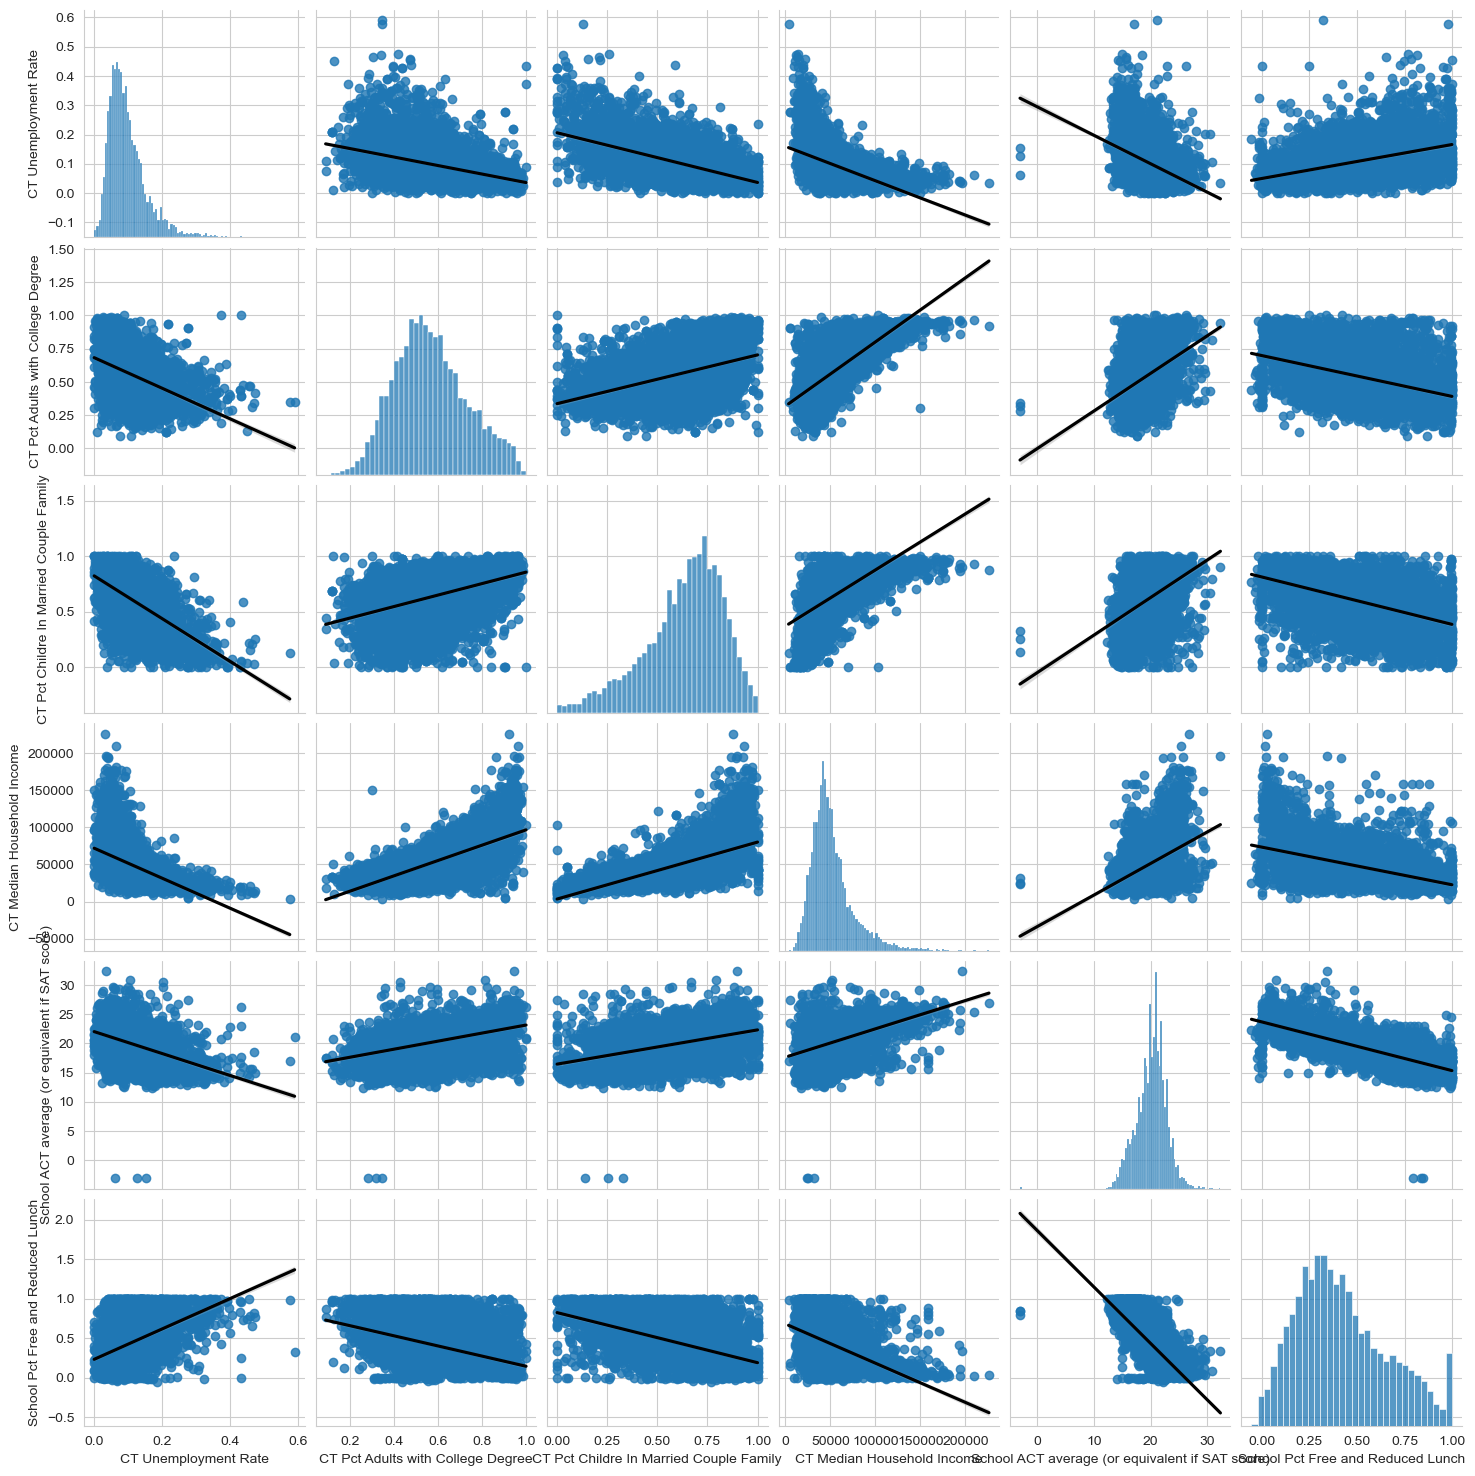

In [9]:
sns.pairplot(
    edgap.drop(columns="NCESSCH School ID"),
    kind="reg",
    plot_kws={
        "line_kws": {"color" : "black"}
    }
);


plt.show()

### Data Formatting

Select relevant features in the data, and rename the columns, using snake_case formatting

In [10]:
school_information = school_information[
    ['SCHOOL_YEAR', 'NCESSCH', 'LSTATE', 'LZIP', 'SCH_TYPE_TEXT', 'LEVEL', 'CHARTER_TEXT']
]

In [11]:
school_information.head()

,SCHOOL_YEAR,NCESSCH,LSTATE,LZIP,SCH_TYPE_TEXT,LEVEL,CHARTER_TEXT
0,2016-2017,1.000020e+10,AL,35220,Alternative School,High,No
1,2016-2017,1.000020e+10,AL,36067,Alternative School,High,No
2,2016-2017,1.000020e+10,AL,36784,Alternative School,High,No
3,2016-2017,1.000020e+10,AL,36057,Alternative School,High,No
4,2016-2017,1.000020e+10,AL,35206,Alternative School,High,No


In [12]:
edgap.columns

Index(['NCESSCH School ID', 'CT Unemployment Rate',
       'CT Pct Adults with College Degree',
       'CT Pct Childre In Married Couple Family', 'CT Median Household Income',
       'School ACT average (or equivalent if SAT score)',
       'School Pct Free and Reduced Lunch'],
      dtype='object')

In [13]:
edgap = edgap.rename(
    columns = {
       'NCESSCH School ID': 'id', 
       'CT Unemployment Rate': 'rate_unemployment',
       'CT Pct Adults with College Degree': 'percent_college',
       'CT Pct Childre In Married Couple Family': 'percent_married', 
       'CT Median Household Income': 'median_income',
       'School ACT average (or equivalent if SAT score)': 'average_act',
       'School Pct Free and Reduced Lunch': 'percent_lunch',
    }
)

In [14]:
edgap.head()

,id,rate_unemployment,percent_college,percent_married,median_income,average_act,percent_lunch
0,100001600143,0.117962,0.445283,0.346495,42820.0,20.433455,0.066901
1,100008000024,0.063984,0.662765,0.767619,89320.0,19.498168,0.112412
2,100008000225,0.056460,0.701864,0.713090,84140.0,19.554335,0.096816
3,100017000029,0.044739,0.692062,0.641283,56500.0,17.737485,0.296960
4,100018000040,0.077014,0.640060,0.834402,54015.0,18.245421,0.262641


In [15]:
school_information.columns

Index(['SCHOOL_YEAR', 'NCESSCH', 'LSTATE', 'LZIP', 'SCH_TYPE_TEXT', 'LEVEL',
       'CHARTER_TEXT'],
      dtype='object')

In [16]:
school_information = school_information.rename(
    columns = {
       'NCESSCH': 'id', 
       'SCHOOL_YEAR': 'year',
       'LSTATE': 'state',
       'LZIP': 'zip_code', 
       'SCH_TYPE_TEXT': 'school_type',
       'LEVEL': 'school_level',
       'CHARTER_TEXT': 'charter',
    }
)

In [17]:
school_information.head()

,year,id,state,zip_code,school_type,school_level,charter
0,2016-2017,1.000020e+10,AL,35220,Alternative School,High,No
1,2016-2017,1.000020e+10,AL,36067,Alternative School,High,No
2,2016-2017,1.000020e+10,AL,36784,Alternative School,High,No
3,2016-2017,1.000020e+10,AL,36057,Alternative School,High,No
4,2016-2017,1.000020e+10,AL,35206,Alternative School,High,No


In [18]:
school_information.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 102183 entries, 0 to 102182
Data columns (total 7 columns):
 #   Column        Non-Null Count   Dtype  
---  ------        --------------   -----  
 0   year          102183 non-null  object 
 1   id            102181 non-null  float64
 2   state         102183 non-null  object 
 3   zip_code      102183 non-null  object 
 4   school_type   102181 non-null  object 
 5   school_level  102179 non-null  object 
 6   charter       102179 non-null  object 
dtypes: float64(1), object(6)
memory usage: 5.5+ MB


### Join the dataframes

In [19]:
school_information['id'] = school_information['id'].astype('object')

In [20]:
school_information.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 102183 entries, 0 to 102182
Data columns (total 7 columns):
 #   Column        Non-Null Count   Dtype 
---  ------        --------------   ----- 
 0   year          102183 non-null  object
 1   id            102181 non-null  object
 2   state         102183 non-null  object
 3   zip_code      102183 non-null  object
 4   school_type   102181 non-null  object
 5   school_level  102179 non-null  object
 6   charter       102179 non-null  object
dtypes: object(7)
memory usage: 5.5+ MB


In [21]:
df = edgap.merge(
    school_information,
    how = 'left', # use the left join
    on = 'id'     # use id as the key
)

In [22]:
df.head()

,id,rate_unemployment,percent_college,percent_married,median_income,average_act,percent_lunch,year,state,zip_code,school_type,school_level,charter
0,100001600143,0.117962,0.445283,0.346495,42820.0,20.433455,0.066901,2016-2017,DE,19804,Regular School,High,Yes
1,100008000024,0.063984,0.662765,0.767619,89320.0,19.498168,0.112412,2016-2017,DE,19709,Regular School,High,No
2,100008000225,0.056460,0.701864,0.713090,84140.0,19.554335,0.096816,2016-2017,DE,19709,Regular School,High,No
3,100017000029,0.044739,0.692062,0.641283,56500.0,17.737485,0.296960,2016-2017,DE,19958,Regular School,High,No
4,100018000040,0.077014,0.640060,0.834402,54015.0,18.245421,0.262641,2016-2017,DE,19934,Regular School,High,No


In [23]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7986 entries, 0 to 7985
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 7986 non-null   object 
 1   rate_unemployment  7972 non-null   float64
 2   percent_college    7973 non-null   float64
 3   percent_married    7961 non-null   float64
 4   median_income      7966 non-null   float64
 5   average_act        7986 non-null   float64
 6   percent_lunch      7986 non-null   float64
 7   year               7898 non-null   object 
 8   state              7898 non-null   object 
 9   zip_code           7898 non-null   object 
 10  school_type        7898 non-null   object 
 11  school_level       7898 non-null   object 
 12  charter            7898 non-null   object 
dtypes: float64(6), object(7)
memory usage: 811.2+ KB


## Quality control

In [24]:
df.describe()

,rate_unemployment,percent_college,percent_married,median_income,average_act,percent_lunch
count,7972.000000,7973.000000,7961.000000,7966.000000,7986.000000,7986.000000
mean,0.098730,0.568930,0.633440,52026.905222,20.181532,0.420651
std,0.058959,0.165704,0.196764,24228.057079,2.595201,0.239754
min,0.000000,0.091493,0.000000,3589.000000,-3.070818,-0.054545
25%,0.058655,0.450828,0.523810,36597.250000,18.600000,0.238501
50%,0.085649,0.554979,0.667594,46833.500000,20.400000,0.381570
75%,0.123376,0.676571,0.777135,61369.250000,21.910867,0.575447
max,0.590278,1.000000,1.000000,226181.000000,32.362637,0.998729


In [25]:
df.select_dtypes(include = ['number']).agg(['min', 'max']).round(2)

,rate_unemployment,percent_college,percent_married,median_income,average_act,percent_lunch
min,0.00,0.09,0.0,3589.0,-3.07,-0.05
max,0.59,1.00,1.0,226181.0,32.36,1.00


Set out of range values to NaN

In [26]:
df.loc[df['percent_lunch'] < 0, 'percent_lunch'] = np.nan

In [27]:
df.loc[df['average_act'] < 1, 'average_act'] = np.nan

Check the types, levels and charter status of schools

In [28]:
df['school_type'].value_counts()

school_type
Regular School                 7885
Alternative School               10
Special Education School          2
Career and Technical School       1
Name: count, dtype: int64

In [29]:
df['school_level'].value_counts()

school_level
High            7230
Other            631
Not reported      35
Elementary         2
Name: count, dtype: int64

In [30]:
df['charter'].value_counts()

charter
No                7329
Yes                352
Not applicable     217
Name: count, dtype: int64

Keep only high schools

In [31]:
df = df.loc[df['school_level'] == 'High'] 

Check for any duplicated rows

In [32]:
df.duplicated().sum()

np.int64(0)

Identify missing values

In [33]:
df.isna().sum().to_frame(name = 'Number of Missing Values')

,Number of Missing Values
id,0
rate_unemployment,12
percent_college,11
percent_married,20
median_income,16
average_act,3
percent_lunch,20
year,0
state,0
zip_code,0


#### Drop the rows where average ACT score is missing

ACT score is the reponse variable of our interest and the percentage of missing values for ACT score is low.

In [34]:
df = df.dropna(subset = ['average_act'])

In [35]:
df.isna().sum().to_frame(name = 'Number of Missing Values')

,Number of Missing Values
id,0
rate_unemployment,12
percent_college,11
percent_married,20
median_income,16
average_act,0
percent_lunch,20
year,0
state,0
zip_code,0


### Data Imputation

In [36]:
predictor_variables = [
    'rate_unemployment', 
    'percent_college', 
    'percent_married', 
    'median_income', 
    'percent_lunch', 
    'state', 
    'charter'
]

In [37]:
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer

In [38]:
imputer = IterativeImputer() #models the variable with missing values as a function of other variables

In [39]:
numerical_predictors = df[predictor_variables].select_dtypes(include = 'number').columns.to_list()
print(numerical_predictors)

['rate_unemployment', 'percent_college', 'percent_married', 'median_income', 'percent_lunch']


In [40]:
imputer.fit(df.loc[:, numerical_predictors]) # learn the relationships between the columns

,estimator,None
,missing_values,nan
,sample_posterior,False
,max_iter,10
,tol,0.001
,n_nearest_features,None
,initial_strategy,'mean'
,fill_value,None
,imputation_order,'ascending'
,skip_complete,False
,min_value,-inf


Impute the missing values in the training data

In [41]:
df.loc[:, numerical_predictors] = imputer.transform(df.loc[:, numerical_predictors])

Check for missing values

In [42]:
df.isna().sum().to_frame(name = 'Number of Missing Values')

,Number of Missing Values
id,0
rate_unemployment,0
percent_college,0
percent_married,0
median_income,0
average_act,0
percent_lunch,0
year,0
state,0
zip_code,0


Export a clean dataset

In [43]:
df.to_csv(
    '/Users/michael/Documents/SeattleU/5100/Education/data/education_clean.csv',
    encoding = 'utf-8-sig',
    index = False
)

### Summary
1. We used an iterative imputer to estimate missing values of numerical predictor variables.
2. We saved the clean data frame as a csv file.

## Modeling

Import relevant libraries

In [44]:
# Import pandas, numpy, and matplotlib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# seaborn is a data visualization library built on matplotlib
import seaborn as sns

# set the plotting style
sns.set_style("whitegrid")

# Model preprocessing
from sklearn.preprocessing import StandardScaler

# Modeling
import statsmodels.formula.api as smf
import statsmodels.api as sm

# Model metrics and analysis
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from statsmodels.stats.anova import anova_lm

In [45]:
df = pd.read_csv("/Users/michael/Documents/SeattleU/5100/Education/data/education_clean.csv")

In [46]:
df.head()

,id,rate_unemployment,percent_college,percent_married,median_income,average_act,percent_lunch,year,state,zip_code,school_type,school_level,charter
0,100001600143,0.117962,0.445283,0.346495,42820.0,20.433455,0.066901,2016-2017,DE,19804,Regular School,High,Yes
1,100008000024,0.063984,0.662765,0.767619,89320.0,19.498168,0.112412,2016-2017,DE,19709,Regular School,High,No
2,100008000225,0.056460,0.701864,0.713090,84140.0,19.554335,0.096816,2016-2017,DE,19709,Regular School,High,No
3,100017000029,0.044739,0.692062,0.641283,56500.0,17.737485,0.296960,2016-2017,DE,19958,Regular School,High,No
4,100018000040,0.077014,0.640060,0.834402,54015.0,18.245421,0.262641,2016-2017,DE,19934,Regular School,High,No


In [72]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7227 entries, 0 to 7226
Data columns (total 17 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   id                            7227 non-null   int64  
 1   rate_unemployment             7227 non-null   float64
 2   percent_college               7227 non-null   float64
 3   percent_married               7227 non-null   float64
 4   median_income                 7227 non-null   float64
 5   average_act                   7227 non-null   float64
 6   percent_lunch                 7227 non-null   float64
 7   year                          7227 non-null   object 
 8   state                         7227 non-null   object 
 9   zip_code                      7227 non-null   int64  
 10  school_type                   7227 non-null   object 
 11  school_level                  7227 non-null   object 
 12  charter                       7227 non-null   object 
 13  med

Create the regression model using the three explanatory variables of interest in this study: median_income, percent_lunch, and percent_college.

In [47]:
model = smf.ols(
    formula = 'average_act ~ median_income + percent_lunch + percent_college',
    data = df).fit()

In [ ]:
results_table = pd.DataFrame({
    'Coefficient': model.params,
    'P-value': model.pvalues
})

# Round results to 4 decimal places
results_table = results_table.round(4)

display(results_table)

,Coefficient,P-value
Intercept,22.3928,0.0000
median_income,0.0000,0.3973
percent_lunch,-7.7543,0.0000
percent_college,1.8155,0.0000


median_income coefficient too small to understand, will convert to be by 10k units

In [49]:
df["median_income"].describe()

count      7227.000000
mean      52745.417759
std       24359.994346
min        1091.668241
25%       37107.000000
50%       47410.000000
75%       62105.000000
max      226181.000000
Name: median_income, dtype: float64

In [50]:
df['median_income_10k'] = df['median_income'] / 10000

In [51]:
model_10k = smf.ols(
    formula = 'average_act ~ median_income_10k + percent_lunch + percent_college',
    data = df).fit()

In [52]:



results_table = pd.DataFrame({
    'Coefficient': model_10k.params,
    'P-value': model_10k.pvalues
})

# Round results to 4 decimal places
results_table = results_table.round(4)

display(results_table)

,Coefficient,P-value
Intercept,22.3928,0.0000
median_income_10k,0.0093,0.3973
percent_lunch,-7.7543,0.0000
percent_college,1.8155,0.0000


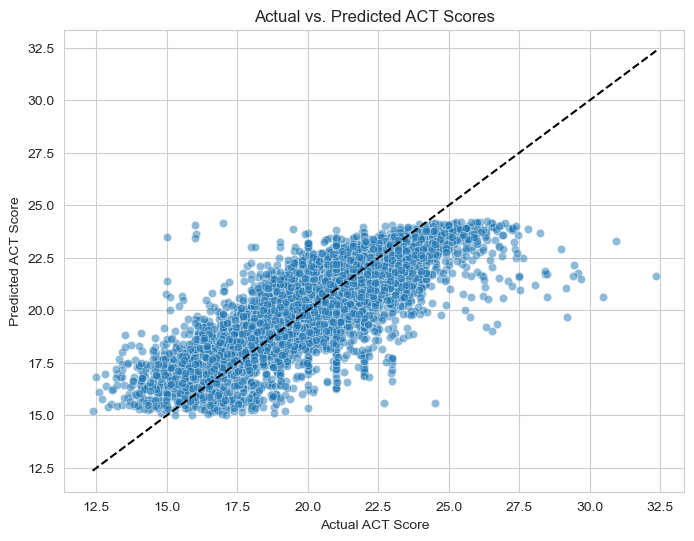

In [53]:
# Get actual and predicted ACT scores
actual = model_10k.model.endog
predicted = model_10k.fittedvalues

# Create scatter plot
plt.figure(figsize=(8, 6))

sns.scatterplot(x=actual, y=predicted, alpha=0.5)

# Add perfect prediction line
plt.plot(
    [min(actual), max(actual)],
    [min(actual), max(actual)],
    color='black',
    linestyle='--'
)

plt.xlabel('Actual ACT Score')
plt.ylabel('Predicted ACT Score')
plt.title('Actual vs. Predicted ACT Scores')

# Save chart as PNG
plt.savefig(
    '/Users/michael/Documents/SeattleU/5100/Education/reports/multiple_regression_model_visual.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()


In [54]:
print(model_10k.summary())

                            OLS Regression Results                            
Dep. Variable:            average_act   R-squared:                       0.626
Model:                            OLS   Adj. R-squared:                  0.626
Method:                 Least Squares   F-statistic:                     4034.
Date:                Wed, 21 Oct 2026   Prob (F-statistic):               0.00
Time:                        13:54:12   Log-Likelihood:                -13344.
No. Observations:                7227   AIC:                         2.670e+04
Df Residuals:                    7223   BIC:                         2.672e+04
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------
Intercept            22.3928      0.09

In [55]:
y_hat = model.predict()

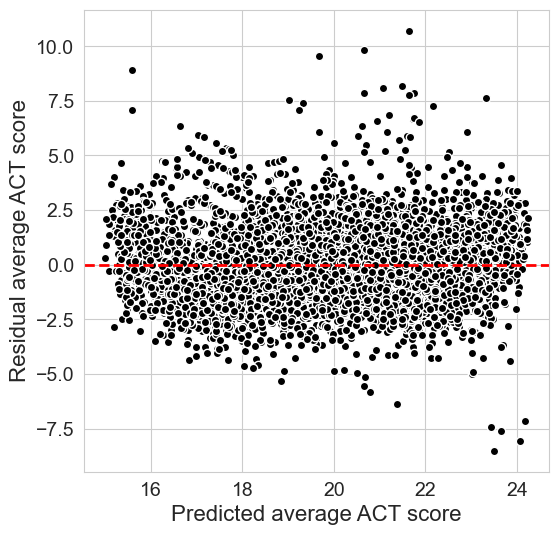

In [56]:
plt.figure(figsize = (6, 6))

plt.plot(y_hat, model.resid, 'ko', mec = 'w')
plt.axhline(0, color = 'r', linestyle = 'dashed', lw = 2)

# Add axis labels
plt.xlabel('Predicted average ACT score', fontsize = 16)
plt.ylabel('Residual average ACT score', fontsize = 16)

# Increase the fontsize of the tick labels
plt.tick_params(labelsize = 14)

plt.savefig('/Users/michael/Documents/SeattleU/5100/Education/reports/multiple_regression_model_residual.png', dpi=300, bbox_inches='tight')

plt.show()

Compute the mean absolute error

In [57]:
mean_absolute_error(df['average_act'], model.predict())

1.1488010006032412

Determine how school median income influences ACT score

In [58]:
model_income = smf.ols(
    formula='average_act ~ median_income_10k',
    data=df
).fit()

print(model_income.summary())

                            OLS Regression Results                            
Dep. Variable:            average_act   R-squared:                       0.211
Model:                            OLS   Adj. R-squared:                  0.211
Method:                 Least Squares   F-statistic:                     1934.
Date:                Wed, 21 Oct 2026   Prob (F-statistic):               0.00
Time:                        13:54:13   Log-Likelihood:                -16043.
No. Observations:                7227   AIC:                         3.209e+04
Df Residuals:                    7225   BIC:                         3.210e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------
Intercept            17.8026      0.06

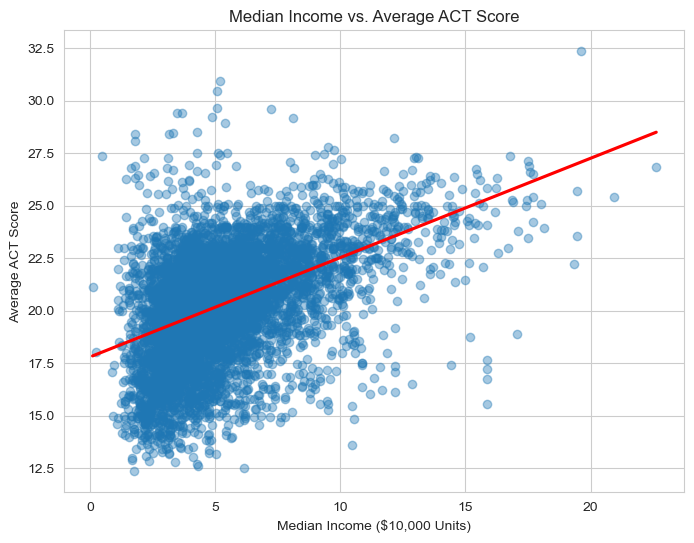

In [59]:
# Create scatter plot with regression line
# Create scatter plot with regression line
plt.figure(figsize=(8, 6))

sns.regplot(
    data=df,
    x='median_income_10k',
    y='average_act',
    scatter_kws={'alpha': 0.4},
    line_kws={'color': 'red'},
    ci=None
)

plt.xlabel('Median Income ($10,000 Units)')
plt.ylabel('Average ACT Score')
plt.title('Median Income vs. Average ACT Score')

plt.show()

## Scaling

The predictor variables will now be scaled to make the coefficients easier to compare

Create a list of the predictor variables

In [60]:
predictor_variables = ['median_income_10k', 'percent_lunch', 'percent_college']

In [61]:
# create a list of names of these scaled columns
scaled_columns = [var + '_normalized' for var in predictor_variables]
print(scaled_columns)

['median_income_10k_normalized', 'percent_lunch_normalized', 'percent_college_normalized']


In [62]:
# standardize/normalize
scaler = StandardScaler().fit(df[predictor_variables])

In [63]:
df[scaled_columns] = scaler.transform(df[predictor_variables])

The mean and standard deviation of the scaled variables are checked to ensure that they are scaled correctly, with a mean of zero and standard deviation of one

In [64]:
df[scaled_columns].agg(['mean', 'std']).round(3)

,median_income_10k_normalized,percent_lunch_normalized,percent_college_normalized
mean,-0.0,0.0,-0.0
std,1.0,1.0,1.0


In [65]:
model_normalized = smf.ols(
    formula = 'average_act ~ percent_college_normalized + median_income_10k_normalized + percent_lunch_normalized',
    data = df).fit()

In [66]:
# Create a table of regression results
results_normalized = pd.DataFrame({
    'Coefficient': model_normalized.params,
    'P-value': model_normalized.pvalues
})

# Round to 4 decimal places
results_normalized = results_normalized.round(4)

# Display table
display(results_normalized)

,Coefficient,P-value
Intercept,20.2986,0.0000
percent_college_normalized,0.2994,0.0000
median_income_10k_normalized,0.0225,0.3973
percent_lunch_normalized,-1.8163,0.0000


In [67]:
print(model_normalized.summary())

                            OLS Regression Results                            
Dep. Variable:            average_act   R-squared:                       0.626
Model:                            OLS   Adj. R-squared:                  0.626
Method:                 Least Squares   F-statistic:                     4034.
Date:                Wed, 21 Oct 2026   Prob (F-statistic):               0.00
Time:                        13:54:48   Log-Likelihood:                -13344.
No. Observations:                7227   AIC:                         2.670e+04
Df Residuals:                    7223   BIC:                         2.672e+04
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                                   coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------------------
Intercept       